In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler

import shap

In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

In [3]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
X.shape

(569, 30)

In [5]:
y.value_counts()

,count
target,
1,357
0,212


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [7]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((455, 30), (114, 30), (455,), (114,))

In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

In [11]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

model.fit(X_train_scaled_df, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [12]:
y_pred = model.predict(X_test_scaled_df)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print(classification_report(y_test, y_pred))

Accuracy: 0.956140350877193
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [13]:
X_explain = X_test_scaled_df.iloc[:20].copy()

In [14]:
background_standard = shap.sample(X_train_scaled_df, 100, random_state=42)

In [15]:
start_time = time.time()

explainer_standard = shap.KernelExplainer(
    model.predict_proba,
    background_standard
)

shap_values_standard = explainer_standard.shap_values(X_explain)

standard_time = time.time() - start_time
print("Standard SHAP runtime:", standard_time)

  0%|          | 0/20 [00:00<?, ?it/s]

Standard SHAP runtime: 18.090492486953735


In [16]:
type(shap_values_standard)

numpy.ndarray

In [17]:
shap_standard_class1 = shap_values_standard[1]

In [18]:
shap_standard_class1 = shap_values_standard[1]

In [19]:
k = 20

In [20]:
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(X_train_scaled_df)

KMeans(n_clusters=20, n_init=10, random_state=42)

In [21]:
background_cshap = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=X.columns
)

In [22]:
background_cshap.head()
background_cshap.shape

(20, 30)

In [23]:
start_time = time.time()

explainer_cshap = shap.KernelExplainer(
    model.predict_proba,
    background_cshap
)

shap_values_cshap = explainer_cshap.shap_values(X_explain)

cshap_time = time.time() - start_time
print("C-SHAP runtime:", cshap_time)

  0%|          | 0/20 [00:00<?, ?it/s]

C-SHAP runtime: 5.51048731803894


In [24]:
shap_cshap_class1 = shap_values_cshap[1]

In [25]:
runtime_df = pd.DataFrame({
    "method": ["Standard SHAP", "C-SHAP (K-means)"],
    "runtime_seconds": [standard_time, cshap_time]
})

runtime_df

,method,runtime_seconds
0,Standard SHAP,18.090492
1,C-SHAP (K-means),5.510487


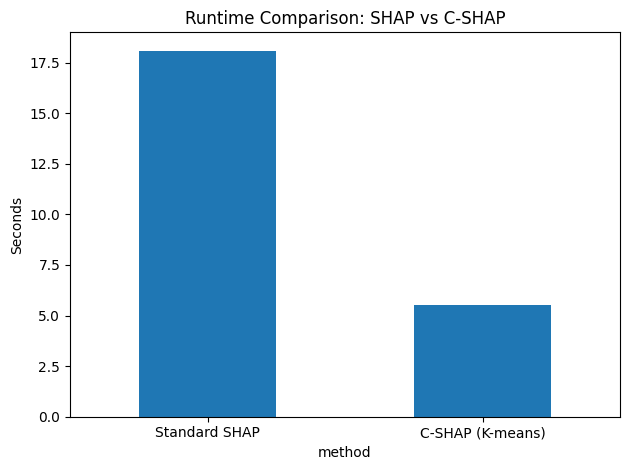

In [26]:
runtime_df.plot(x="method", y="runtime_seconds", kind="bar", legend=False)
plt.title("Runtime Comparison: SHAP vs C-SHAP")
plt.ylabel("Seconds")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("runtime_comparison.png", bbox_inches="tight")
plt.show()

In [31]:
shap_standard_class1 = shap_values_standard[:, :, 1]
shap_cshap_class1 = shap_values_cshap[:, :, 1]

In [32]:
print("standard shap shape:", np.array(shap_standard_class1).shape)
print("cshap shap shape:", np.array(shap_cshap_class1).shape)

standard shap shape: (20, 30)
cshap shap shape: (20, 30)


In [33]:
global_standard = np.abs(shap_standard_class1).mean(axis=0)
global_cshap = np.abs(shap_cshap_class1).mean(axis=0)

In [34]:
print(len(global_standard))
print(len(global_cshap))
print(len(X.columns))

30
30
30


In [35]:
importance_df = pd.DataFrame({
    "feature": X.columns,
    "standard_shap": global_standard,
    "cshap": global_cshap
})

In [36]:
importance_df = importance_df.sort_values(by="standard_shap", ascending=False)
importance_df.head(10)

,feature,standard_shap,cshap
23,worst area,0.072036,0.072554
22,worst perimeter,0.070012,0.069832
27,worst concave points,0.057723,0.058944
20,worst radius,0.057182,0.060506
7,mean concave points,0.037493,0.036110
6,mean concavity,0.032045,0.027759
13,area error,0.027329,0.024241
3,mean area,0.024408,0.022020
26,worst concavity,0.021203,0.020704
21,worst texture,0.015415,0.012337


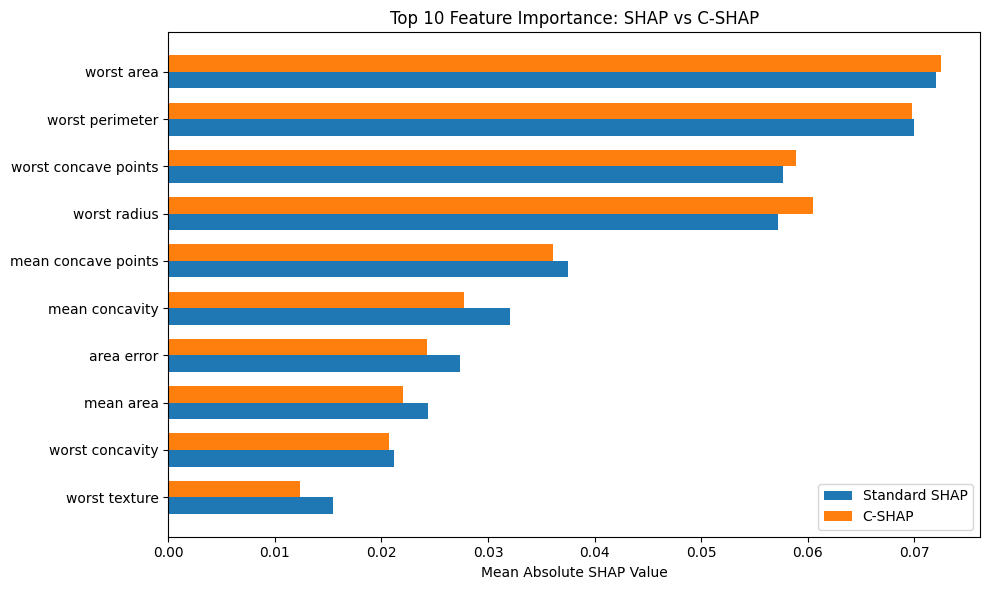

In [38]:
top10_df = importance_df.head(10).copy()
top10_df = top10_df.sort_values(by="standard_shap", ascending=True)

x = np.arange(len(top10_df))
width = 0.35

plt.figure(figsize=(10, 6))
plt.barh(x - width/2, top10_df["standard_shap"], height=width, label="Standard SHAP")
plt.barh(x + width/2, top10_df["cshap"], height=width, label="C-SHAP")
plt.yticks(x, top10_df["feature"])
plt.xlabel("Mean Absolute SHAP Value")
plt.title("Top 10 Feature Importance: SHAP vs C-SHAP")
plt.legend()
plt.tight_layout()
plt.savefig("feature_importance_comparison.png", bbox_inches="tight")
plt.show()

In [39]:
correlation = np.corrcoef(global_standard, global_cshap)[0, 1]
print("Correlation between SHAP and C-SHAP global importance:", correlation)

Correlation between SHAP and C-SHAP global importance: 0.9972858102331273


In [40]:
mad = np.mean(np.abs(global_standard - global_cshap))
print("Mean absolute difference:", mad)

Mean absolute difference: 0.0009759206748030782


In [41]:
accuracy
standard_time
cshap_time
correlation

np.float64(0.9972858102331273)

In [42]:
importance_df.head(10)

,feature,standard_shap,cshap
23,worst area,0.072036,0.072554
22,worst perimeter,0.070012,0.069832
27,worst concave points,0.057723,0.058944
20,worst radius,0.057182,0.060506
7,mean concave points,0.037493,0.036110
6,mean concavity,0.032045,0.027759
13,area error,0.027329,0.024241
3,mean area,0.024408,0.022020
26,worst concavity,0.021203,0.020704
21,worst texture,0.015415,0.012337


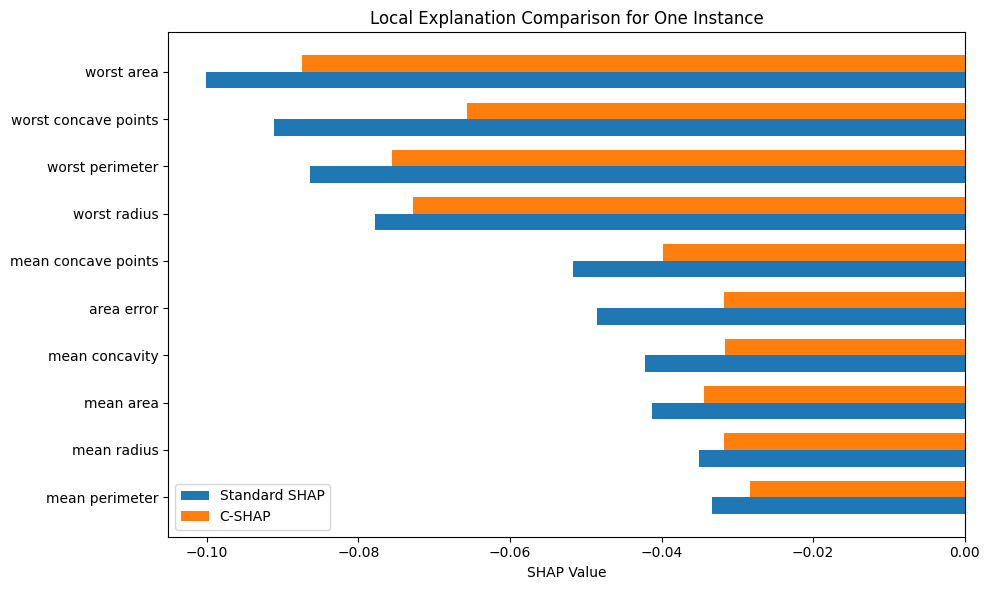

In [43]:
sample_idx = 0

local_df = pd.DataFrame({
    "feature": X.columns,
    "standard_shap": shap_standard_class1[sample_idx],
    "cshap": shap_cshap_class1[sample_idx]
})

local_df["abs_standard"] = np.abs(local_df["standard_shap"])
local_df = local_df.sort_values(by="abs_standard", ascending=False).head(10)

plot_df = local_df.sort_values(by="abs_standard", ascending=True)

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(10, 6))
plt.barh(x - width/2, plot_df["standard_shap"], height=width, label="Standard SHAP")
plt.barh(x + width/2, plot_df["cshap"], height=width, label="C-SHAP")
plt.yticks(x, plot_df["feature"])
plt.xlabel("SHAP Value")
plt.title("Local Explanation Comparison for One Instance")
plt.legend()
plt.tight_layout()
plt.savefig("local_explanation_comparison.png", bbox_inches="tight")
plt.show()

In [44]:
insights = """
# Interpretability Insights from SHAP vs C-SHAP Analysis

This project compares standard SHAP with a C-SHAP-style approximation using K-means clustering to reduce the size of the background dataset.

## Key Interpretability Insights

### 1. Standard SHAP provides detailed explanations but can be slow
Standard SHAP produces informative feature attributions, but explanation generation may become computationally expensive when the background dataset is large.

### 2. K-means clustering can reduce explanation runtime
Using K-means centroids as background representatives reduces the number of reference points used by SHAP, making explanation generation faster.

### 3. C-SHAP can preserve much of the global explanation structure
Despite using a compressed background, the C-SHAP-style method can still produce feature importance rankings that remain highly correlated with standard SHAP.

### 4. Clustering offers a practical trade-off between speed and fidelity
The results suggest that background compression through clustering can improve efficiency without severely sacrificing interpretability quality.

### 5. This approach is useful for scalable interpretability
For larger tabular datasets, C-SHAP-style approximation may provide a more practical interpretability solution when explanation time is important.

## Research Value

This experiment demonstrates a simple but meaningful approximation strategy for scalable explainability. It shows how clustering can be integrated into SHAP-based workflows to balance runtime efficiency and explanation fidelity.
"""

with open("business_insights.md", "w", encoding="utf-8") as f:
    f.write(insights)

print("business_insights.md created")

business_insights.md created


In [45]:
req = """pandas
numpy
scikit-learn
matplotlib
shap
jupyter
"""

with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(req)

print("requirements.txt created")

requirements.txt created
